<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/08_Phishing_Detection/HybridQNN_PhishingURL_Gaurav2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hybrid QNN for phishing-URL detection: Gaurav et al. (2026) step by step

This notebook re-implements, runs and checks the method of

> Akshat Gaurav, Varsha Arya, Brij B. Gupta and Kwok Tai Chui,
> "Hybrid Quantum-AI Model for Robust Phishing Detection in Next-Generation Consumer Electronics",
> 2026 International Conference on Quantum Communications, Networking, and Computing (QCNC), IEEE, 2026, pp. 702-707.
> DOI 10.1109/QCNC69040.2026.00113

The paper publishes no code, so everything below is written from the five-page description (Eqs. 1-13, Fig. 1-8, Table I).

**What the notebook does.** It downloads the UCI *Phishing Websites* data set (11,055 URLs, 30 hand-crafted features), splits it
80/20 as the paper's confusion matrix implies (2,211 test URLs), and builds the paper's hybrid network: a classical embedding
block (30 -> p numbers) -> a **4-qubit parametric circuit** (data-driven `RY`/`RZ` rotations, `L` trainable `RY`/`RZ` layers,
a ring of CNOTs, Pauli-Z read-out) -> concatenation of embedding and quantum features -> fully connected `ReLU` layers -> two
outputs (phishing / safe). The circuit is simulated exactly with PennyLane and trained end to end with PyTorch (back-propagation
through the simulator). The notebook then re-draws the paper's Fig. 2-8, compares the accuracy / F1 / AUC / confusion matrix
with the paper's numbers, trains the same network **without** the quantum layer, and trains three classical baselines on the
identical 30 inputs.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. The first cell installs
pinned versions of PennyLane and Qiskit (Qiskit is only used to cross-check the drawn circuit); if Colab asks you to restart
the session, do so and run all again. No GPU, no IBM Quantum account and no Hugging Face token are needed (the data set is
public on the UCI repository, with an OpenML mirror as fallback).

**Runtime.** `FAST_MODE = True` (2,500 training URLs, 6 epochs, one seed) takes about 2 minutes. `FAST_MODE = False` is the
full run (8,844 training URLs, 30 epochs, three seeds; 10 to 15 minutes on a laptop CPU, almost all of it the exact simulation of the 4-qubit circuit).

**What you get at the end.** The data-set plots, the drawn 4-qubit circuit with its qubit / depth / parameter counts, the
learned `RY`/`RZ` parameters, Pauli-Z expectations and Bloch vectors, the classification report, confusion matrix and ROC
curve, the quantum-vs-no-quantum ablation, and a table that sets every number of the paper beside ours with a verdict.

## The paper in one page

**Problem.** Decide whether a URL seen by a consumer-electronics device (smart-home gadget, IoT hub, phone) is *phishing* or
*safe*.

**Decision.** Binary classification of a pre-computed 30-dimensional feature vector.

**Method (Section III, Eqs. 1-13).**
1. *Embedding* `h = ReLU(W2 ReLU(W1 x + b1) + b2)`, a two-layer feed-forward network that maps `x in R^30` to `h in R^p`.
2. *Quantum layer.* `h` is split into groups of `n_q` values per qubit. Each qubit is first rotated by `RY(theta_i)` then
   `RZ(phi_i)` with `theta_i`, `phi_i` taken from `h` (Eq. 4); then `L` layers of trainable `RY`/`RZ` rotations each followed by
   a CNOT ring `CNOT(i, (i+1) mod n_q)` (Eqs. 7-8); finally every qubit is measured in the Z basis, `z_i = <Z_i>` (Eq. 9).
3. *Hybrid vector* `v = [h, z]` (Eq. 12) -> `u = ReLU(W3 v + b3)` (Eq. 13) -> output layer with two classes (safe / phishing).

**Data.** UCI "Phishing Websites" (Mohammad and McCluskey, 2012; DOI 10.24432/C51W2X): 11,055 URLs, 30 features coded
`-1 / 0 / 1`, label `-1` = phishing (4,898), `1` = legitimate (6,157).

**Claims.**

| Claim | Where | Value |
|---|---|---|
| Accuracy | Abstract, Fig. 6, Conclusion | 94 % (the confusion matrix gives 2,069 / 2,211 = 93.6 %) |
| F1 score | Abstract, Table I | 0.9357 |
| AUC | Abstract, Fig. 8 | 0.9829 (both classes) |
| Phishing precision / recall / F1 | Fig. 6 | 0.94 / 0.91 / 0.92 |
| Normal precision / recall / F1 | Fig. 6 | 0.93 / 0.95 / 0.94 |
| Macro avg precision / recall / F1 | Fig. 6 | 0.94 / 0.94 / 0.93 |
| Confusion matrix (test set of 2,211) | Fig. 7 | `[[872, 84], [58, 1197]]`, rows Actual (Phishing, Normal), columns Predicted |
| Qubits | Table I | 4 (vs 32 for Shahriyar et al., 5 for Ray et al.) |
| F1 of prior quantum models | Table I | 0.67 (Shahriyar), 0.89 (Ray); proposed 0.9357 |
| Learned `RY`/`RZ` values, Pauli-Z expectations | Fig. 2-4 | small angles (about -0.05 to 0.1 for `RY`, -0.1 to 0.2 for `RZ`); `<Z>` between 0 and 0.5, qubit 3 highest, qubit 1 lowest |

### What follows the paper and what had to be chosen

The paper does not give most hyper-parameters. Every choice below is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Data set | UCI Phishing Websites | same (UCI id 327, via `ucimlrepo`; OpenML id 4534 as mirror) |
| Split | not stated; Fig. 7 sums to 2,211 = 20 % of 11,055 | stratified 80 / 20, `random_state=SEED`; 10 % of the training part held out for choosing the best epoch |
| Preprocessing | "data preprocessing" (not described) | none: features are already `-1/0/1`; label phishing = 1 |
| Embedding | 2 layers, ReLU, `p` unspecified | 30 -> 32 -> 8 with ReLU (`p = 2 n_q = 8`: one `RY` and one `RZ` input angle per qubit) |
| Qubits | 4 | 4 |
| Input encoding | `RZ(phi) RY(theta) |0>`, `theta`, `phi` from `h` | `RY(h_i)` then `RZ(h_(4+i))` on qubit `i` (embedding values used directly as angles) |
| Trainable layers `L` | "multiple layers", unspecified | `L = 3`, each qubit `RY(w) RZ(w)` then CNOT ring |
| Entanglement | CNOT ring `i -> (i+1) mod n_q` | same, applied for `i = 0..3` in order |
| Read-out | `<Z_i>` for each qubit | same (exact expectation values, no shot noise) |
| Head | `ReLU(W3 [h, z] + b3)` then output layer | 12 -> 32 ReLU -> 2 logits |
| Loss, optimiser | not stated | cross-entropy, Adam, learning rate 5e-3, batch 256 |
| Epochs | not stated | 30 (full) / 6 (FAST) |
| Quantum simulation | not stated (Fig. 5 Bloch spheres suggest a state-vector simulator) | PennyLane `default.qubit`, exact, back-propagation, torch |
| Seeds | not stated | 3 seeds (full), 1 seed (FAST); mean +- std |
| Classical baselines | none | the same network without the quantum layer, Random Forest, SVC (RBF), logistic regression, all on the same 30 inputs |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib and torch.
# The pip line runs on Colab (or wherever PennyLane is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    %pip install -q "pennylane==0.45.1" "qiskit==2.5.2" pylatexenc ucimlrepo
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("PennyLane already present; skipping pip install.")

PennyLane already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE   = False           # True: class demo in a few minutes. False: full run (30 epochs, 3 seeds, 10 to 15 min on a laptop CPU).
SEED        = 42              # master seed (data split, weights, shuffling)
N_QUBITS    = 4               # paper: 4-qubit circuit
N_LAYERS    = 3               # CHOICE: number of trainable RY/RZ + CNOT-ring layers L (paper: "multiple layers")
EMB_HIDDEN  = 32              # CHOICE: width of the first embedding layer
HEAD_HIDDEN = 32              # CHOICE: width of the post-quantum fully connected layer
TEST_SIZE   = 0.20            # CHOICE: 20 % test (Fig. 7 sums to 2,211 = 20 % of 11,055)
VAL_SIZE    = 0.10            # CHOICE: share of the training part used to pick the best epoch (never the test set)
BATCH_SIZE  = 256             # CHOICE
LR          = 5e-3            # CHOICE: Adam learning rate
EPOCHS      = 6 if FAST_MODE else 30        # CHOICE
SEEDS       = [SEED] if FAST_MODE else [SEED, SEED + 1, SEED + 2]   # repeated runs for mean +- std
TRAIN_CAP   = 2500 if FAST_MODE else None   # FAST_MODE: use at most this many training URLs
DATA_DIR    = "data_QC079"    # downloads are cached here
IBM_TOKEN   = ""              # not used: the paper's circuit is simulated exactly; no hardware run
print(dict(FAST_MODE=FAST_MODE, EPOCHS=EPOCHS, SEEDS=SEEDS, TRAIN_CAP=TRAIN_CAP))

{'FAST_MODE': False, 'EPOCHS': 30, 'SEEDS': [42, 43, 44], 'TRAIN_CAP': None}


In [3]:
import os, time, copy, random, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn
import pennylane as qml
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, roc_auc_score, roc_curve,
                             confusion_matrix, f1_score)
from IPython.display import display

warnings.filterwarnings("ignore", category=UserWarning)
torch.set_default_dtype(torch.float64)       # exact simulation: keep complex128 amplitudes
torch.set_num_threads(max(1, (os.cpu_count() or 2) // 2))
DATA_DIR = Path(DATA_DIR); DATA_DIR.mkdir(parents=True, exist_ok=True)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)

set_seed(SEED)
rng = np.random.default_rng(SEED)
print("numpy", np.__version__, "| pandas", pd.__version__, "| sklearn", sklearn.__version__, "| torch", torch.__version__,
      "| pennylane", qml.__version__)

numpy 2.5.4 | pandas 3.0.6 | sklearn 1.9.1 | torch 2.14.1+cpu | pennylane 0.45.1


## 1. Data: the UCI Phishing Websites set

Mohammad and McCluskey's data set has one row per website. The 30 features are hand-crafted checks of the URL and the page
(IP address instead of domain name, URL length, `@` symbol, SSL certificate state, domain age, traffic rank, ...), each coded
`-1` (looks like phishing), `0` (suspicious) or `1` (looks legitimate). The label `Result` is `-1` for phishing and `1` for a
legitimate site. We recode it to `1 = phishing` (the attack is the positive class, as in the repository conventions).

In [4]:
def load_uci_phishing():
    csv = DATA_DIR / "uci327_phishing_websites.csv"
    if csv.exists():
        return pd.read_csv(csv)
    try:
        from ucimlrepo import fetch_ucirepo               # UCI repository, dataset id 327
        ds = fetch_ucirepo(id=327)
        df = ds.data.features.copy()
        df["result"] = ds.data.targets.iloc[:, 0].values
        src = "UCI repository via ucimlrepo (id 327)"
    except Exception as e:                                # fallback: OpenML mirror of the same file
        print("ucimlrepo failed (", type(e).__name__, ") -> using the OpenML mirror")
        from sklearn.datasets import fetch_openml
        fr = fetch_openml(data_id=4534, as_frame=True, data_home=str(DATA_DIR)).frame
        fr.columns = [c.lower() for c in fr.columns]
        df = fr.apply(pd.to_numeric)
        src = "OpenML id 4534"
    df.to_csv(csv, index=False)
    print("downloaded from", src)
    return df

raw = load_uci_phishing()
raw.columns = [c.strip().lower() for c in raw.columns]
FEATURES = [c for c in raw.columns if c != "result"]
assert len(FEATURES) == 30 and set(raw["result"].unique()) == {-1, 1}
y_all = (raw["result"].values == -1).astype(int)             # 1 = phishing, 0 = legitimate (safe)
X_all = raw[FEATURES].values.astype(float)
print("rows x columns:", raw.shape, "| features:", len(FEATURES), "| missing values:", int(raw.isna().sum().sum()))
print("exact duplicate rows (features + label):", int(raw.duplicated().sum()))

rows x columns: (11055, 31) | features: 30 | missing values: 0
exact duplicate rows (features + label): 5206


Before any modelling we split the data. Everything that is *fitted* (the PCA used for plotting below, every network, the
baselines) sees the training part only; a further 10 % of the training part (`val`) chooses the best training epoch.

In [5]:
idx = np.arange(len(y_all))
tr_idx, te_idx = train_test_split(idx, test_size=TEST_SIZE, stratify=y_all, random_state=SEED)
fit_idx, val_idx = train_test_split(tr_idx, test_size=VAL_SIZE, stratify=y_all[tr_idx], random_state=SEED)
if TRAIN_CAP is not None and len(fit_idx) > TRAIN_CAP:                      # FAST_MODE only
    fit_idx, _ = train_test_split(fit_idx, train_size=TRAIN_CAP, stratify=y_all[fit_idx], random_state=SEED)
X_fit, y_fit = X_all[fit_idx], y_all[fit_idx]
X_val, y_val = X_all[val_idx], y_all[val_idx]
X_te,  y_te  = X_all[te_idx],  y_all[te_idx]
X_tr,  y_tr  = X_all[tr_idx],  y_all[tr_idx]
print(f"fit {len(y_fit)} | val {len(y_val)} | test {len(y_te)}   (phishing share: "
      f"{y_fit.mean():.3f} / {y_val.mean():.3f} / {y_te.mean():.3f})")

fit 7959 | val 885 | test 2211   (phishing share: 0.443 / 0.443 / 0.443)


## Dataset Exploration and Visualisation

All plots below use the real URLs of the UCI data set and their ground-truth label; nothing is simulated.

In [6]:
print("shape of the full data set:", raw.shape)
print("feature names:", FEATURES)
print("value domain per feature:", {c: sorted(raw[c].unique().tolist()) for c in FEATURES[:4]}, "...")
print("\noriginal label values (column 'result'):")
print(raw["result"].value_counts().rename({-1: "-1 (phishing)", 1: " 1 (legitimate)"}))
display(raw.head())

shape of the full data set: (11055, 31)
feature names: ['having_ip_address', 'url_length', 'shortining_service', 'having_at_symbol', 'double_slash_redirecting', 'prefix_suffix', 'having_sub_domain', 'sslfinal_state', 'domain_registration_length', 'favicon', 'port', 'https_token', 'request_url', 'url_of_anchor', 'links_in_tags', 'sfh', 'submitting_to_email', 'abnormal_url', 'redirect', 'on_mouseover', 'rightclick', 'popupwindow', 'iframe', 'age_of_domain', 'dnsrecord', 'web_traffic', 'page_rank', 'google_index', 'links_pointing_to_page', 'statistical_report']
value domain per feature: {'having_ip_address': [-1, 1], 'url_length': [-1, 0, 1], 'shortining_service': [-1, 1], 'having_at_symbol': [-1, 1]} ...

original label values (column 'result'):
result
 1 (legitimate)    6157
-1 (phishing)      4898
Name: count, dtype: int64


,having_ip_address,url_length,shortining_service,having_at_symbol,double_slash_redirecting,prefix_suffix,having_sub_domain,sslfinal_state,domain_registration_length,favicon,...,popupwindow,iframe,age_of_domain,dnsrecord,web_traffic,page_rank,google_index,links_pointing_to_page,statistical_report,result
0,-1,1,1,1,-1,-1,-1,-1,-1,1,...,1,1,-1,-1,-1,-1,1,1,-1,-1
1,1,1,1,1,1,-1,0,1,-1,1,...,1,1,-1,-1,0,-1,1,1,1,-1
2,1,0,1,1,1,-1,-1,-1,-1,1,...,1,1,1,-1,1,-1,1,0,-1,-1
3,1,0,1,1,1,-1,-1,-1,1,1,...,1,1,-1,-1,1,-1,1,-1,1,-1
4,1,0,-1,1,1,-1,1,1,-1,1,...,-1,1,-1,-1,0,-1,1,1,1,1


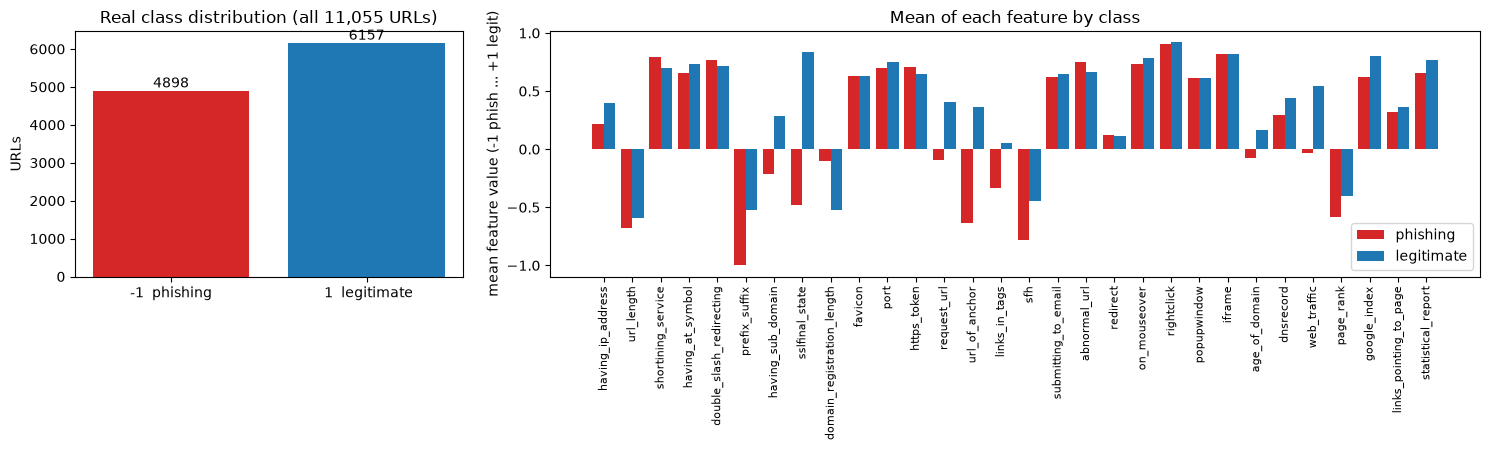

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw=dict(width_ratios=[1, 2.4]))
counts = raw["result"].value_counts().reindex([-1, 1])
bars = axes[0].bar(["-1  phishing", " 1  legitimate"], counts.values, color=["tab:red", "tab:blue"])
axes[0].bar_label(bars)
axes[0].set_ylabel("URLs"); axes[0].set_title("Real class distribution (all 11,055 URLs)")
means = pd.DataFrame(X_all, columns=FEATURES).groupby(y_all).mean()
xs = np.arange(len(FEATURES)); w = 0.4
axes[1].bar(xs - w/2, means.loc[1].values, w, color="tab:red", label="phishing")
axes[1].bar(xs + w/2, means.loc[0].values, w, color="tab:blue", label="legitimate")
axes[1].set_xticks(xs); axes[1].set_xticklabels(FEATURES, rotation=90, fontsize=8)
axes[1].set_ylabel("mean feature value (-1 phish ... +1 legit)"); axes[1].set_title("Mean of each feature by class"); axes[1].legend()
plt.tight_layout(); plt.show()

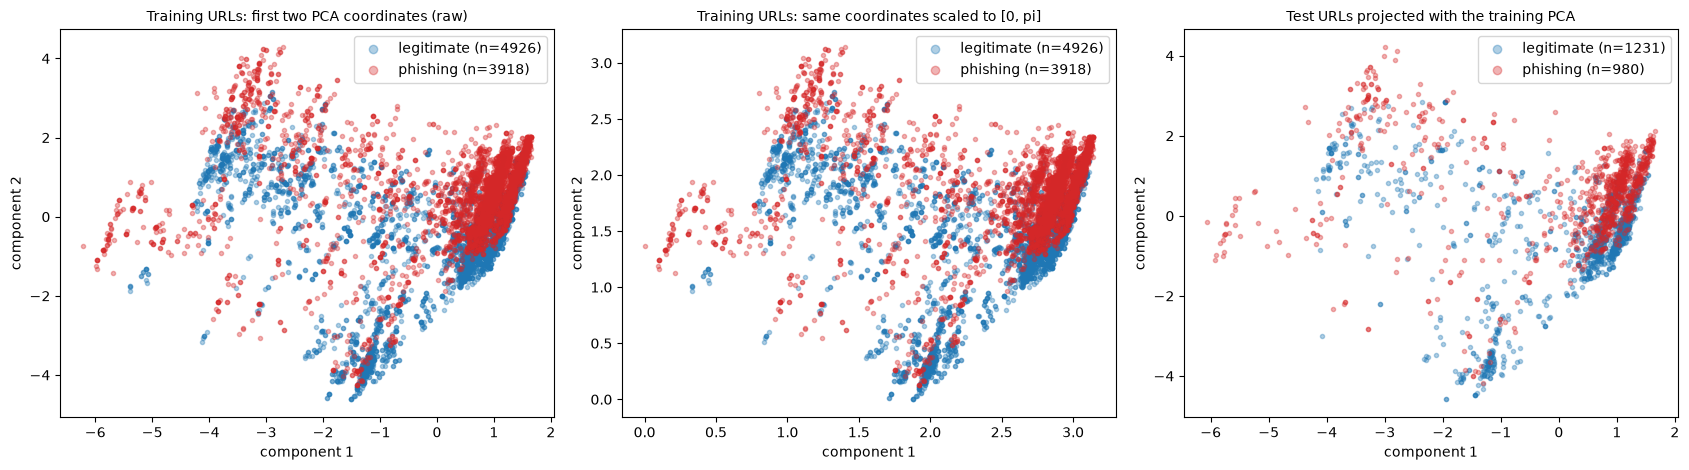

explained variance of the two PCA components: [0.154 0.117]
Features take only the values -1/0/1, so many URLs share the same coordinates (points overlap; alpha shows density).
The paper's circuit does NOT encode PCA angles: its angles are learned by the embedding network; they are plotted in section 7.


In [8]:
# 2-D view of the real URLs, coloured by ground truth. PCA is fitted on the TRAINING part only.
pca = PCA(n_components=2, random_state=SEED).fit(X_tr)
P_tr, P_te = pca.transform(X_tr), pca.transform(X_te)
ang = MinMaxScaler((0, np.pi)).fit(P_tr)                        # CHOICE: only for illustration, see below
A_tr, A_te = np.clip(ang.transform(P_tr), 0, np.pi), np.clip(ang.transform(P_te), 0, np.pi)
names = {1: "phishing", 0: "legitimate"}; cols = {1: "tab:red", 0: "tab:blue"}
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, (A, yy, ttl) in zip(axes, [(P_tr, y_tr, "Training URLs: first two PCA coordinates (raw)"),
                                  (A_tr, y_tr, "Training URLs: same coordinates scaled to [0, pi]"),
                                  (P_te, y_te, "Test URLs projected with the training PCA")]):
    for k in (0, 1):
        m = yy == k
        ax.scatter(A[m, 0], A[m, 1], s=9, alpha=0.35, c=cols[k], label=f"{names[k]} (n={m.sum()})")
    ax.set_title(ttl, fontsize=10); ax.set_xlabel("component 1"); ax.set_ylabel("component 2"); ax.legend(markerscale=2)
plt.tight_layout(); plt.show()
print("explained variance of the two PCA components:", np.round(pca.explained_variance_ratio_, 3))
print("Features take only the values -1/0/1, so many URLs share the same coordinates (points overlap; alpha shows density).")
print("The paper's circuit does NOT encode PCA angles: its angles are learned by the embedding network; they are plotted in section 7.")

## 2. Classical baselines on the identical 30 inputs

The paper reports no classical reference. We train three standard classifiers on exactly the data the hybrid network sees
(`X_fit`, 30 features) and score them on the same test URLs. These numbers are what the quantum layer has to be compared with.

In [9]:
def report(y_true, p_phish, thr=0.5):
    # metrics in the paper's layout: class 'Phishing' first, then 'Normal' (safe); phishing is the positive class
    pred = (p_phish >= thr).astype(int)
    pr, rc, f1, _ = precision_recall_fscore_support(y_true, pred, labels=[1, 0], zero_division=0)
    sup = np.array([(y_true == 1).sum(), (y_true == 0).sum()])
    cm = confusion_matrix(y_true, pred, labels=[1, 0])          # rows actual (phish, normal), cols predicted (phish, normal)
    return dict(acc=accuracy_score(y_true, pred), auc=roc_auc_score(y_true, p_phish),
                p_ph=pr[0], r_ph=rc[0], f1_ph=f1[0], p_no=pr[1], r_no=rc[1], f1_no=f1[1],
                macro_p=pr.mean(), macro_r=rc.mean(), macro_f1=f1.mean(), weighted_f1=np.average(f1, weights=sup),
                tp=cm[0, 0], fn=cm[0, 1], fp=cm[1, 0], tn=cm[1, 1], errors=int(cm[0, 1] + cm[1, 0]))

rows = []
baselines = {
    "RandomForest (300 trees)": lambda s: RandomForestClassifier(n_estimators=100 if FAST_MODE else 300, random_state=s, n_jobs=1),
    "SVC (RBF, C=1)":           lambda s: SVC(kernel="rbf", C=1.0, random_state=s),
    "LogisticRegression":       lambda s: LogisticRegression(max_iter=2000, random_state=s),
}
for name, make in baselines.items():
    for s in SEEDS:
        t0 = time.perf_counter(); mdl = make(s).fit(X_fit, y_fit)
        score = mdl.predict_proba(X_te)[:, 1] if hasattr(mdl, "predict_proba") else 1 / (1 + np.exp(-mdl.decision_function(X_te)))
        rows.append(dict(model=name, seed=s, seconds=time.perf_counter() - t0, **report(y_te, score)))
base_df = pd.DataFrame(rows)
show = ["acc", "weighted_f1", "macro_f1", "auc", "p_ph", "r_ph", "f1_ph", "errors", "seconds"]
display(base_df.groupby("model")[show].agg(["mean", "std"]).round(4))

acc         weighted_f1         macro_f1          \
                            mean     std        mean     std     mean     std   
model                                                                           
LogisticRegression        0.9285  0.0000      0.9284  0.0000   0.9273  0.0000   
RandomForest (300 trees)  0.9751  0.0009      0.9751  0.0009   0.9748  0.0009   
SVC (RBF, C=1)            0.9471  0.0000      0.9470  0.0000   0.9462  0.0000   

                             auc            p_ph           r_ph          \
                            mean     std    mean    std    mean     std   
model                                                                     
LogisticRegression        0.9785  0.0000  0.9363  0.000  0.9000  0.0000   
RandomForest (300 trees)  0.9965  0.0002  0.9803  0.001  0.9633  0.0018   
SVC (RBF, C=1)            0.9890  0.0000  0.9537  0.000  0.9255  0.0000   

                           f1_ph        errors      seconds          
                            mean    std   mean  std    mean     std  
model                                                                
LogisticRegression        0.9178  0.000  158.0  0.0  0.1441  0.0111  
RandomForest (300 trees)  0.9717  0.001   55.0  2.0  4.9257  0.2476  
SVC (RBF, C=1)            0.9394  0.000  117.0  0.0  5.3319  0.3452

## Quantum Circuit Architecture

This is the circuit that is executed on every forward pass of the hybrid network (PennyLane `default.qubit`, exact state
vector). For one URL it takes the 8 embedding numbers `h = (h_0..h_7)` as *data* angles and the `L x 4 x 2` trainable weights,
and returns the four Pauli-Z expectations.

* **Encoding (Eq. 4).** On qubit `i`: `RY(h_i)` then `RZ(h_(4+i))`, i.e. `RZ(phi_i) RY(theta_i) |0>`.
* **Trainable layers (Eq. 7).** On every qubit `RY(w_(l,i,0))` then `RZ(w_(l,i,1))`, followed by the CNOT ring
  `CNOT(0,1) CNOT(1,2) CNOT(2,3) CNOT(3,0)` (Eq. 8). Repeated `L = 3` times.
* **Measurement (Eq. 9).** `<Z>` on each of the 4 qubits.

*Assumptions where the paper is silent:* the number of layers `L`, the initial weights (normal, std 0.1, so that the circuit
starts near the identity, in line with the small values of Fig. 2-3), the order of the CNOTs inside a ring (ascending `i`),
and that the embedding values are used directly as angles (no scaling).

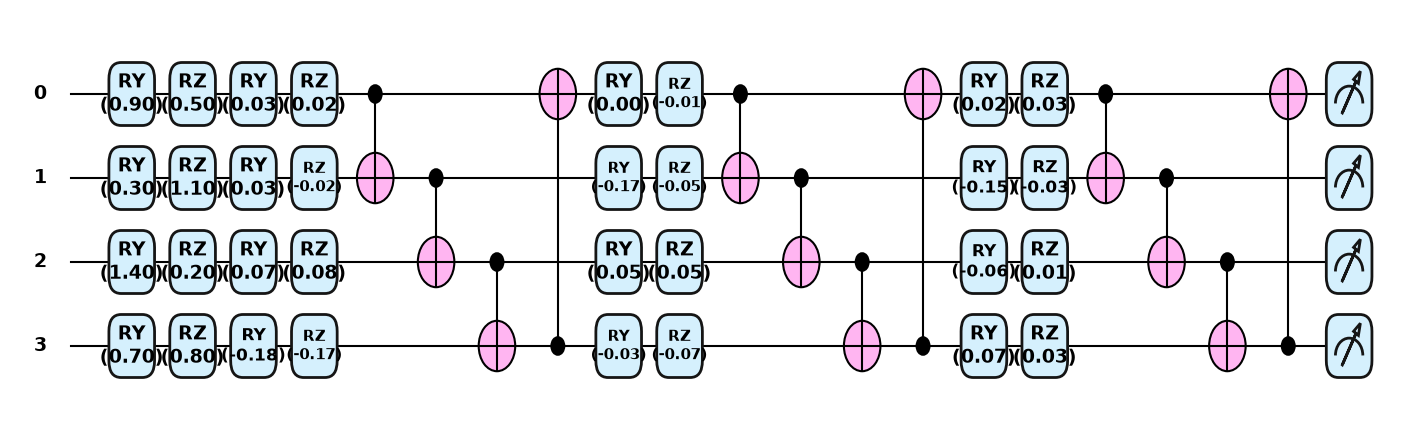

qubits: 4 | circuit depth: 20 | gates: {'RY': 16, 'RZ': 16, 'CNOT': 12}
trainable quantum parameters: 24 (= L x n_q x 2 = 3 x 4 x 2); data angles per URL: 8


In [10]:
dev = qml.device("default.qubit", wires=N_QUBITS)

def circuit_body(inputs, weights):
    # data encoding, Eq. (4): RZ(phi_i) RY(theta_i) |0>  with theta_i = h_i and phi_i = h_(n_q+i)   # CHOICE: ordering of h
    for i in range(N_QUBITS):
        qml.RY(inputs[..., i], wires=i)
        qml.RZ(inputs[..., N_QUBITS + i], wires=i)
    # L trainable layers, Eq. (7), each ending with the CNOT ring of Eq. (8)
    for l in range(N_LAYERS):
        for i in range(N_QUBITS):
            qml.RY(weights[l, i, 0], wires=i)
            qml.RZ(weights[l, i, 1], wires=i)
        for i in range(N_QUBITS):
            qml.CNOT(wires=[i, (i + 1) % N_QUBITS])

@qml.qnode(dev, interface="torch", diff_method="backprop")
def qnode(inputs, weights):
    circuit_body(inputs, weights)
    return [qml.expval(qml.PauliZ(i)) for i in range(N_QUBITS)]

@qml.qnode(dev, interface="torch", diff_method="backprop")
def qnode_bloch(inputs, weights):                 # same circuit, X/Y/Z of every qubit (for Fig. 5)
    circuit_body(inputs, weights)
    return [qml.expval(op(i)) for i in range(N_QUBITS) for op in (qml.PauliX, qml.PauliY, qml.PauliZ)]

demo_inputs  = torch.tensor([0.9, 0.3, 1.4, 0.7, 0.5, 1.1, 0.2, 0.8])        # one example embedding (for drawing only)
demo_weights = 0.1 * torch.randn(N_LAYERS, N_QUBITS, 2, generator=torch.Generator().manual_seed(SEED))
fig, ax = qml.draw_mpl(qnode, decimals=2, style="pennylane")(demo_inputs, demo_weights)
fig.set_size_inches(14, 4.2); plt.show()

specs = qml.specs(qnode)(demo_inputs, demo_weights)
res = specs["resources"] if isinstance(specs, dict) else specs.resources
print("qubits:", N_QUBITS, "| circuit depth:", res.depth, "| gates:", dict(res.gate_types))
print("trainable quantum parameters:", demo_weights.numel(), f"(= L x n_q x 2 = {N_LAYERS} x {N_QUBITS} x 2); data angles per URL: {2 * N_QUBITS}")

In [11]:
# Equivalence check: rebuild the same gate sequence in Qiskit and compare the <Z_i> values with the PennyLane QNode.
try:
    from qiskit import QuantumCircuit
    from qiskit.quantum_info import Statevector, Pauli
    def qiskit_z(h, w):
        qc = QuantumCircuit(N_QUBITS)
        for i in range(N_QUBITS):
            qc.ry(float(h[i]), i); qc.rz(float(h[N_QUBITS + i]), i)
        for l in range(N_LAYERS):
            for i in range(N_QUBITS):
                qc.ry(float(w[l, i, 0]), i); qc.rz(float(w[l, i, 1]), i)
            for i in range(N_QUBITS):
                qc.cx(i, (i + 1) % N_QUBITS)
        sv = Statevector(qc)
        return np.array([sv.expectation_value(Pauli("I" * (N_QUBITS - 1 - i) + "Z" + "I" * i)).real for i in range(N_QUBITS)])
    g = torch.Generator().manual_seed(SEED)
    for _ in range(5):
        h = 2 * torch.rand(2 * N_QUBITS, generator=g); w = 0.5 * torch.randn(N_LAYERS, N_QUBITS, 2, generator=g)
        a = torch.stack(qnode(h, w)).detach().numpy(); b = qiskit_z(h.numpy(), w.numpy())
        assert np.allclose(a, b, atol=1e-8), (a, b)
    print("PennyLane QNode and an independent Qiskit statevector circuit agree on 5 random inputs (atol 1e-8).")
except ImportError:
    print("Qiskit not installed: equivalence check skipped (the drawn circuit is the executed PennyLane QNode).")

PennyLane QNode and an independent Qiskit statevector circuit agree on 5 random inputs (atol 1e-8).


## 3. The hybrid network and its training

`HybridNet` is Eq. 1 with the quantum layer switched on or off. With `use_quantum=False` the circuit is removed and the head
sees only the embedding `h` (an otherwise identical classical network): this is the ablation that tells us how much the 4
qubits contribute. The embedding output is fed to the circuit as angles, so gradients flow from the loss through the exact
simulator (back-propagation) into the embedding weights and the circuit weights together.

In [12]:
class HybridNet(nn.Module):
    def __init__(self, use_quantum=True):
        super().__init__()
        self.use_quantum = use_quantum
        p = 2 * N_QUBITS                                                   # CHOICE: p = 2 n_q (one RY and one RZ angle per qubit)
        self.emb = nn.Sequential(nn.Linear(30, EMB_HIDDEN), nn.ReLU(), nn.Linear(EMB_HIDDEN, p), nn.ReLU())   # Eq. (2)
        if use_quantum:
            self.qw = nn.Parameter(0.1 * torch.randn(N_LAYERS, N_QUBITS, 2))   # CHOICE: small normal initial weights
        head_in = p + (N_QUBITS if use_quantum else 0)                     # v = [h, z], Eq. (12)
        self.head = nn.Sequential(nn.Linear(head_in, HEAD_HIDDEN), nn.ReLU(), nn.Linear(HEAD_HIDDEN, 2))   # Eq. (13) + output layer
    def features(self, x):
        h = self.emb(x)
        z = torch.stack(qnode(h, self.qw), dim=-1) if self.use_quantum else None
        return h, z
    def forward(self, x):
        h, z = self.features(x)
        v = torch.cat([h, z], dim=-1) if self.use_quantum else h
        return self.head(v)

def n_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)
set_seed(SEED)
for q in (True, False):
    m = HybridNet(q); print(f"use_quantum={q}: {n_params(m)} trainable parameters" + (f" (of which {m.qw.numel()} in the circuit)" if q else ""))

use_quantum=True: 1762 trainable parameters (of which 24 in the circuit)
use_quantum=False: 1610 trainable parameters


In [13]:
def predict_proba(model, X, bs=1024):
    model.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(X), bs):
            out.append(torch.softmax(model(torch.tensor(X[i:i + bs])), dim=-1)[:, 1].numpy())
    return np.concatenate(out)

def train_one(use_quantum, seed):
    set_seed(seed)
    model = HybridNet(use_quantum)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    lossf = nn.CrossEntropyLoss()
    Xf, yf = torch.tensor(X_fit), torch.tensor(y_fit)
    Xv, yv = torch.tensor(X_val), torch.tensor(y_val)
    gen = torch.Generator().manual_seed(seed)
    hist, best, best_state = [], np.inf, None
    t0 = time.perf_counter()
    for ep in range(1, EPOCHS + 1):
        model.train(); perm = torch.randperm(len(Xf), generator=gen); run = 0.0
        for i in range(0, len(Xf), BATCH_SIZE):
            b = perm[i:i + BATCH_SIZE]
            opt.zero_grad(); loss = lossf(model(Xf[b]), yf[b]); loss.backward(); opt.step()
            run += loss.item() * len(b)
        model.eval()
        with torch.no_grad():
            lv = model(Xv); val_loss = lossf(lv, yv).item(); val_acc = (lv.argmax(1) == yv).double().mean().item()
        hist.append(dict(epoch=ep, train_loss=run / len(Xf), val_loss=val_loss, val_acc=val_acc))
        if val_loss < best: best, best_state, best_ep = val_loss, copy.deepcopy(model.state_dict()), ep
        print(f"  [{'hybrid' if use_quantum else 'no-quantum'} seed {seed}] epoch {ep:2d}/{EPOCHS}  train loss {hist[-1]['train_loss']:.4f}"
              f"  val loss {val_loss:.4f}  val acc {val_acc:.4f}  ({time.perf_counter() - t0:.0f}s)")
    model.load_state_dict(best_state)
    return model, pd.DataFrame(hist), best_ep, time.perf_counter() - t0

In [14]:
runs = {}        # (variant, seed) -> dict(model, hist, best_epoch, seconds, p_test)
net_rows = []
for s in SEEDS:
    for variant, uq in (("Hybrid QNN (4 qubits)", True), ("Same network, no quantum layer", False)):
        model, hist, best_ep, secs = train_one(uq, s)
        t0 = time.perf_counter(); p = predict_proba(model, X_te); t_pred = time.perf_counter() - t0
        runs[(variant, s)] = dict(model=model, hist=hist, best_epoch=best_ep, seconds=secs, p_test=p)
        net_rows.append(dict(model=variant, seed=s, seconds=secs + t_pred, best_epoch=best_ep, **report(y_te, p)))
net_df = pd.DataFrame(net_rows)
display(net_df[["model", "seed", "best_epoch", "acc", "weighted_f1", "auc", "errors", "seconds"]].round(4))

  [hybrid seed 42] epoch  1/30  train loss 0.4152  val loss 0.1897  val acc 0.9367  (5s)


  [hybrid seed 42] epoch  2/30  train loss 0.1900  val loss 0.1573  val acc 0.9446  (9s)


  [hybrid seed 42] epoch  3/30  train loss 0.1724  val loss 0.1920  val acc 0.9209  (15s)


  [hybrid seed 42] epoch  4/30  train loss 0.1724  val loss 0.1447  val acc 0.9412  (22s)


  [hybrid seed 42] epoch  5/30  train loss 0.1579  val loss 0.1374  val acc 0.9514  (26s)


...

  [no-quantum seed 44] epoch 27/30  train loss 0.0894  val loss 0.0949  val acc 0.9514  (19s)


  [no-quantum seed 44] epoch 28/30  train loss 0.0895  val loss 0.0911  val acc 0.9638  (20s)


  [no-quantum seed 44] epoch 29/30  train loss 0.0847  val loss 0.1030  val acc 0.9582  (21s)


  [no-quantum seed 44] epoch 30/30  train loss 0.0836  val loss 0.0904  val acc 0.9559  (21s)


,model,seed,best_epoch,acc,weighted_f1,auc,errors,seconds
0,Hybrid QNN (4 qubits),42,23,0.9616,0.9615,0.9940,85,242.7609
1,"Same network, no quantum layer",42,29,0.9620,0.9620,0.9928,84,43.1887
2,Hybrid QNN (4 qubits),43,27,0.9566,0.9565,0.9930,96,251.3566
3,"Same network, no quantum layer",43,29,0.9597,0.9597,0.9933,89,50.5688
4,Hybrid QNN (4 qubits),44,26,0.9584,0.9584,0.9923,92,176.2730
5,"Same network, no quantum layer",44,30,0.9588,0.9588,0.9942,91,21.2335


## 4. Metrics, confusion matrix and ROC curve (the paper's Fig. 6, 7, 8)

The paper lists the classes as *Phishing* then *Normal* and reports precision, recall and F1 per class, the macro and weighted
averages, the confusion matrix with rows = actual class, and one ROC curve. We reproduce all three for the first seed of the
hybrid network; the tables average over all seeds.

Classification report of the hybrid QNN, seed 42 (paper's Fig. 6)


,Precision,Recall,F1 score
Phishing,0.9745,0.9378,0.9558
Normal,0.9519,0.9805,0.9660
Accuracy,NaN,NaN,0.9616
Macro avg,0.9632,0.9591,0.9609
Weighted avg,0.9619,0.9616,0.9615


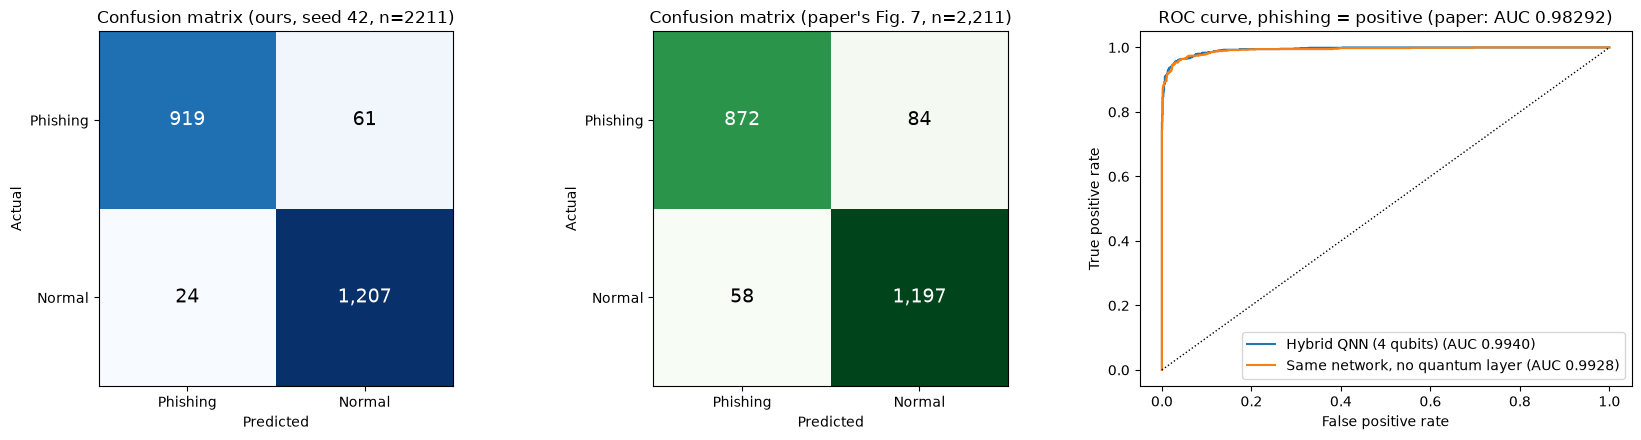

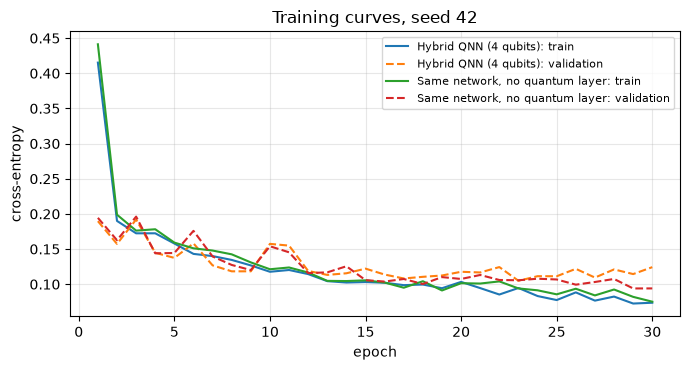

Mean and std over 3 seed(s)


acc         weighted_f1         macro_f1  \
                                  mean     std        mean     std     mean   
model                                                                         
Hybrid QNN (4 qubits)           0.9588  0.0025      0.9588  0.0025   0.9582   
Same network, no quantum layer  0.9602  0.0016      0.9602  0.0016   0.9597   

                                           auc            p_ph          ...  \
                                   std    mean     std    mean     std  ...   
model                                                                   ...   
Hybrid QNN (4 qubits)           0.0025  0.9931  0.0008  0.9656  0.0099  ...   
Same network, no quantum layer  0.0016  0.9934  0.0007  0.9576  0.0047  ...   

                                  p_no            r_no           f1_no  \
                                  mean     std    mean     std    mean   
model                                                                    
Hybrid QNN (4 qubits)           0.9539  0.0065  0.9732  0.0082  0.9634   
Same network, no quantum layer  0.9623  0.0023  0.9664  0.0040  0.9643   

                                       errors           seconds           
                                   std   mean     std      mean      std  
model                                                                     
Hybrid QNN (4 qubits)           0.0023   91.0  5.5678  223.4635  41.0935  
Same network, no quantum layer  0.0015   88.0  3.6056   38.3303  15.2592  

[2 rows x 24 columns]

In [15]:
HY, NQ = "Hybrid QNN (4 qubits)", "Same network, no quantum layer"
s0 = SEEDS[0]; p0 = runs[(HY, s0)]["p_test"]; rep0 = report(y_te, p0)
# Fig. 6: classification report (phishing first), seed s0
cls = pd.DataFrame({"Precision": [rep0["p_ph"], rep0["p_no"], np.nan, rep0["macro_p"]],
                    "Recall": [rep0["r_ph"], rep0["r_no"], np.nan, rep0["macro_r"]],
                    "F1 score": [rep0["f1_ph"], rep0["f1_no"], rep0["acc"], rep0["macro_f1"]]},
                   index=["Phishing", "Normal", "Accuracy", "Macro avg"])
cls.loc["Weighted avg"] = [np.average([rep0["p_ph"], rep0["p_no"]], weights=[(y_te == 1).sum(), (y_te == 0).sum()]),
                           np.average([rep0["r_ph"], rep0["r_no"]], weights=[(y_te == 1).sum(), (y_te == 0).sum()]), rep0["weighted_f1"]]
print(f"Classification report of the hybrid QNN, seed {s0} (paper's Fig. 6)"); display(cls.round(4))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
cm = np.array([[rep0["tp"], rep0["fn"]], [rep0["fp"], rep0["tn"]]])
axes[0].imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2): axes[0].text(j, i, f"{cm[i, j]:,}", ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=14)
axes[0].set_xticks([0, 1]); axes[0].set_xticklabels(["Phishing", "Normal"]); axes[0].set_yticks([0, 1]); axes[0].set_yticklabels(["Phishing", "Normal"])
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual"); axes[0].set_title(f"Confusion matrix (ours, seed {s0}, n={len(y_te)})")
paper_cm = np.array([[872, 84], [58, 1197]])
axes[1].imshow(paper_cm, cmap="Greens")
for i in range(2):
    for j in range(2): axes[1].text(j, i, f"{paper_cm[i, j]:,}", ha="center", va="center", color="white" if paper_cm[i, j] > 600 else "black", fontsize=14)
axes[1].set_xticks([0, 1]); axes[1].set_xticklabels(["Phishing", "Normal"]); axes[1].set_yticks([0, 1]); axes[1].set_yticklabels(["Phishing", "Normal"])
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("Actual"); axes[1].set_title("Confusion matrix (paper's Fig. 7, n=2,211)")
for (v, s), r in runs.items():
    fpr, tpr, _ = roc_curve(y_te, r["p_test"])
    if s == s0: axes[2].plot(fpr, tpr, label=f"{v} (AUC {roc_auc_score(y_te, r['p_test']):.4f})")
axes[2].plot([0, 1], [0, 1], "k:", lw=1); axes[2].set_xlabel("False positive rate"); axes[2].set_ylabel("True positive rate")
axes[2].set_title(f"ROC curve, phishing = positive (paper: AUC 0.98292)"); axes[2].legend(loc="lower right")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(7, 3.8))
for (v, s), r in runs.items():
    if s == s0:
        ax.plot(r["hist"].epoch, r["hist"].train_loss, label=f"{v}: train"); ax.plot(r["hist"].epoch, r["hist"].val_loss, "--", label=f"{v}: validation")
ax.set_xlabel("epoch"); ax.set_ylabel("cross-entropy"); ax.set_title(f"Training curves, seed {s0}"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
summary = net_df.groupby("model")[["acc", "weighted_f1", "macro_f1", "auc", "p_ph", "r_ph", "f1_ph", "p_no", "r_no", "f1_no", "errors", "seconds"]].agg(["mean", "std"])
print(f"Mean and std over {len(SEEDS)} seed(s)"); display(summary.round(4))

## 5. Inside the quantum layer (the paper's Fig. 2, 3, 4)

After training we read out what the circuit learned: the trainable `RY` and `RZ` angles per layer and qubit (Fig. 2, 3) and
the mean Pauli-Z expectation per qubit over the test URLs (Fig. 4). The paper's axes ("Layer 0.0 ... 1.0") are not layer
indices; we plot against the layer number `1..L`.

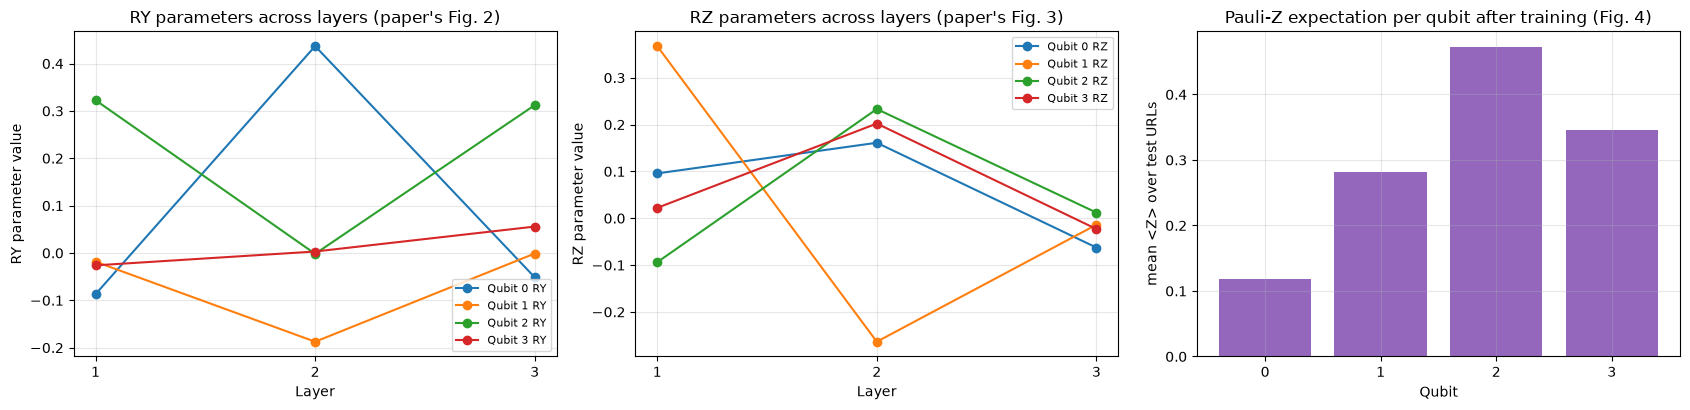

trained circuit weights, range: RY [-0.187, 0.437]  RZ [-0.264, 0.368]
mean <Z_i> per qubit: [0.118 0.282 0.473 0.345] | highest qubit: 2 | lowest qubit: 0
std of <Z_i> over test URLs: [0.675 0.512 0.526 0.653] (non-zero std: the circuit output depends on the URL, it has not collapsed)


In [16]:
mdl = runs[(HY, s0)]["model"]; W = mdl.qw.detach().numpy()          # (L, n_q, 2)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
layers = np.arange(1, N_LAYERS + 1)
for i in range(N_QUBITS):
    axes[0].plot(layers, W[:, i, 0], "o-", label=f"Qubit {i} RY"); axes[1].plot(layers, W[:, i, 1], "o-", label=f"Qubit {i} RZ")
axes[0].set_title("RY parameters across layers (paper's Fig. 2)"); axes[1].set_title("RZ parameters across layers (paper's Fig. 3)")
for a, lab in zip(axes[:2], ("RY", "RZ")):
    a.set_xticks(layers); a.set_xlabel("Layer"); a.set_ylabel(f"{lab} parameter value"); a.legend(fontsize=8); a.grid(alpha=0.3)
with torch.no_grad():
    _, Z = mdl.features(torch.tensor(X_te)); Z = Z.numpy()
zmean = Z.mean(0)
axes[2].bar(range(N_QUBITS), zmean, color="tab:purple"); axes[2].set_xticks(range(N_QUBITS)); axes[2].set_xlabel("Qubit")
axes[2].set_ylabel("mean <Z> over test URLs"); axes[2].set_title("Pauli-Z expectation per qubit after training (Fig. 4)"); axes[2].grid(alpha=0.3)
plt.tight_layout(); plt.show()
print("trained circuit weights, range: RY [%.3f, %.3f]  RZ [%.3f, %.3f]" % (W[..., 0].min(), W[..., 0].max(), W[..., 1].min(), W[..., 1].max()))
print("mean <Z_i> per qubit:", np.round(zmean, 3), "| highest qubit:", int(zmean.argmax()), "| lowest qubit:", int(zmean.argmin()))
print("std of <Z_i> over test URLs:", np.round(Z.std(0), 3), "(non-zero std: the circuit output depends on the URL, it has not collapsed)")

## 6. Bloch vectors of the four qubits (the paper's Fig. 5)

Because the CNOT ring entangles the qubits, the reduced state of each qubit is generally *mixed* and its Bloch vector lies
inside the sphere. For every test URL we compute `(<X_i>, <Y_i>, <Z_i>)` from the same circuit; the plot shows 300 real test
URLs per qubit, coloured by ground truth, and the mean vector as a black arrow.

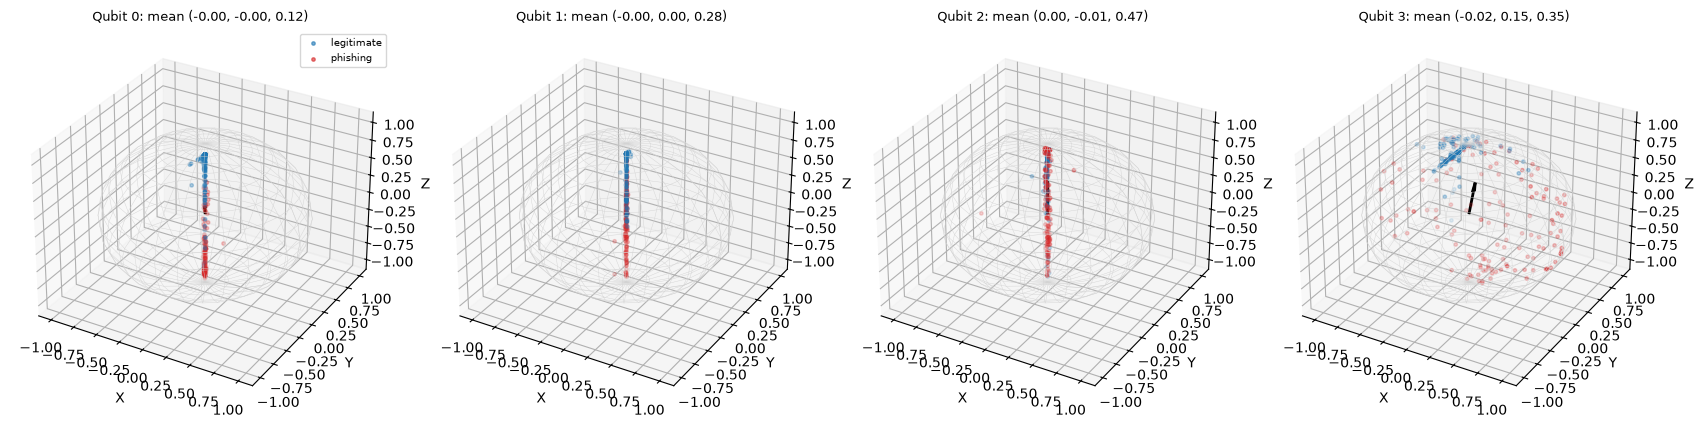

mean length of the Bloch vector per qubit (1 = pure, <1 = entangled with the rest): [0.637 0.499 0.646 0.874]


In [17]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
with torch.no_grad():
    Hh, _ = mdl.features(torch.tensor(X_te))
    B = torch.stack(qnode_bloch(Hh, mdl.qw), dim=-1).numpy().reshape(len(X_te), N_QUBITS, 3)
sel = np.random.default_rng(SEED).choice(len(X_te), size=min(300, len(X_te)), replace=False)
u, v = np.mgrid[0:2 * np.pi:30j, 0:np.pi:15j]
fig = plt.figure(figsize=(17, 4.6))
for i in range(N_QUBITS):
    ax = fig.add_subplot(1, N_QUBITS, i + 1, projection="3d")
    ax.plot_wireframe(np.cos(u) * np.sin(v), np.sin(u) * np.sin(v), np.cos(v), color="lightgray", lw=0.3)
    for k in (0, 1):
        m = y_te[sel] == k
        ax.scatter(B[sel][m, i, 0], B[sel][m, i, 1], B[sel][m, i, 2], s=6, c=cols[k], alpha=0.6, label=names[k])
    mb = B[:, i, :].mean(0); ax.quiver(0, 0, 0, *mb, color="k", lw=2)
    ax.set_title(f"Qubit {i}: mean ({mb[0]:.2f}, {mb[1]:.2f}, {mb[2]:.2f})", fontsize=9); ax.set_xlabel("X"); ax.set_ylabel("Y"); ax.set_zlabel("Z")
    if i == 0: ax.legend(fontsize=7)
plt.tight_layout(); plt.show()
print("mean length of the Bloch vector per qubit (1 = pure, <1 = entangled with the rest):", np.round(np.linalg.norm(B, axis=2).mean(0), 3))

## 7. What the embedding and the circuit make of real URLs

The paper's circuit does not encode PCA coordinates; its input angles are produced by the embedding network. Here are the
real test URLs, coloured by ground truth, in (a) the first two learned *encoding angles* (`RY` angles of qubit 0 and qubit 1,
radians) and (b) the first two *quantum features* `z_0, z_1` that the circuit returns.

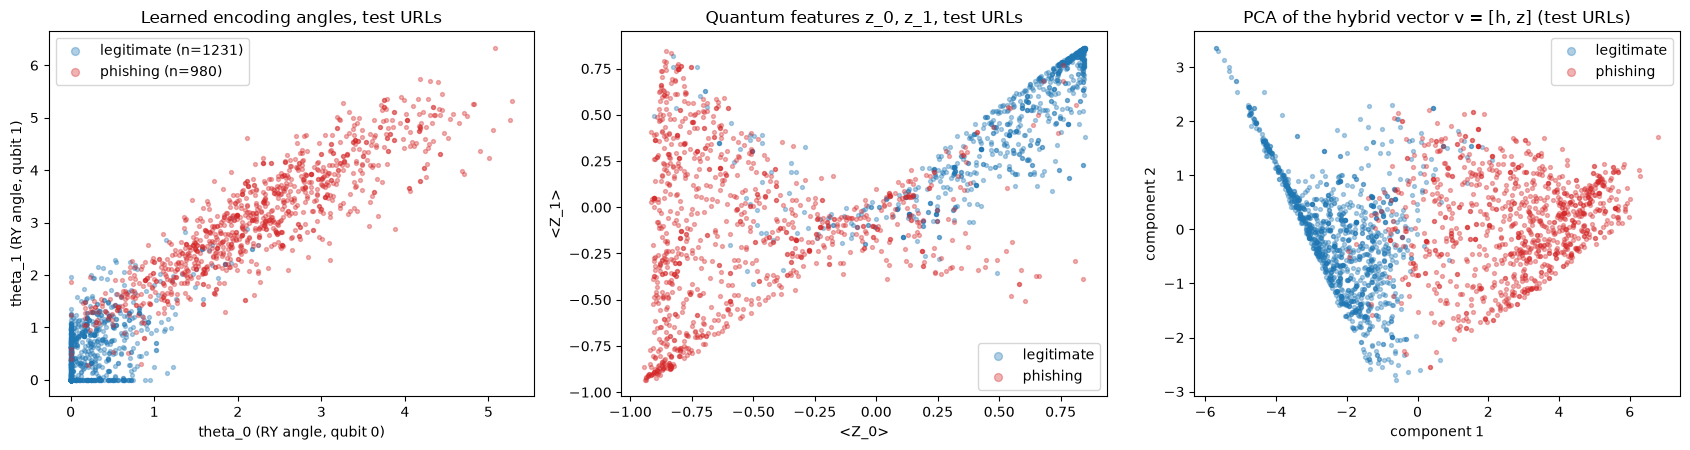

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
Hn = Hh.numpy()
for k in (0, 1):
    m = y_te == k
    axes[0].scatter(Hn[m, 0], Hn[m, 1], s=8, alpha=0.35, c=cols[k], label=f"{names[k]} (n={m.sum()})")
    axes[1].scatter(Z[m, 0], Z[m, 1], s=8, alpha=0.35, c=cols[k], label=names[k])
axes[0].set_xlabel("theta_0 (RY angle, qubit 0)"); axes[0].set_ylabel("theta_1 (RY angle, qubit 1)"); axes[0].set_title("Learned encoding angles, test URLs")
axes[1].set_xlabel("<Z_0>"); axes[1].set_ylabel("<Z_1>"); axes[1].set_title("Quantum features z_0, z_1, test URLs")
pz = PCA(n_components=2, random_state=SEED).fit(np.hstack([Hn, Z]))
V = pz.transform(np.hstack([Hn, Z]))
for k in (0, 1):
    m = y_te == k; axes[2].scatter(V[m, 0], V[m, 1], s=8, alpha=0.35, c=cols[k], label=names[k])
axes[2].set_title("PCA of the hybrid vector v = [h, z] (test URLs)"); axes[2].set_xlabel("component 1"); axes[2].set_ylabel("component 2")
for a in axes: a.legend(markerscale=2)
plt.tight_layout(); plt.show()

## 8. Side by side with the paper

Rule: a number is *reproduced* when it lies within 0.02 (accuracy, F1, precision, recall, AUC) of the paper's value; otherwise
*not reached* (we are lower) or *exceeded* (we are higher) with the gap. The paper's accuracy is stated as 94 %, but its own
confusion matrix gives 93.6 %; both are shown. The paper's "F1 score 0.9357" (abstract, Table I) equals the matrix accuracy
(0.9358) and is within 0.001 of its weighted-average F1, so we compare it with our weighted F1.

In [19]:
hyb = net_df[net_df.model == HY]
def mean_std(col): return hyb[col].mean(), hyb[col].std(ddof=0) if len(hyb) > 1 else 0.0
paper = [  # (claim, paper value, notebook column, tolerance)
    ("Accuracy (stated 94 %)", 0.94, "acc"), ("Accuracy from Fig. 7 (2069/2211)", 2069 / 2211, "acc"),
    ("F1 score (abstract, Table I; weighted F1)", 0.9357, "weighted_f1"), ("AUC (Fig. 8)", 0.9829, "auc"),
    ("Phishing precision (Fig. 6)", 0.94, "p_ph"), ("Phishing recall (Fig. 6)", 0.91, "r_ph"), ("Phishing F1 (Fig. 6)", 0.92, "f1_ph"),
    ("Normal precision (Fig. 6)", 0.93, "p_no"), ("Normal recall (Fig. 6)", 0.95, "r_no"), ("Normal F1 (Fig. 6)", 0.94, "f1_no"),
    ("Macro-average F1 (Fig. 6)", 0.93, "macro_f1"),
]
out = []
for claim, pv, col in paper:
    m, sd = mean_std(col); gap = m - pv
    verdict = "reproduced" if abs(gap) <= 0.02 else ("exceeded" if gap > 0 else "not reached")
    out.append(dict(claim=claim, paper=round(pv, 4), notebook=f"{m:.4f} +- {sd:.4f}", gap=round(gap, 4), verdict=verdict))
m_err, sd_err = mean_std("errors")
out.append(dict(claim="Misclassified of 2,211 test URLs (Fig. 7: 84 + 58)", paper=142, notebook=f"{m_err:.1f} +- {sd_err:.1f}",
                gap=round(m_err - 142, 1), verdict="reproduced" if abs(m_err - 142) <= 0.02 * 2211 else ("exceeded (fewer errors)" if m_err < 142 else "not reached")))
out.append(dict(claim="Circuit size: 4 qubits (Table I)", paper=4, notebook=N_QUBITS, gap=0, verdict="reproduced"))
# qualitative claims on the trained circuit (Figs. 2-4): seed-dependent, so judged on the first seed
rngW = (W.min(), W.max())
out.append(dict(claim="Quantum features non-trivial: 0 < |mean <Z>| < 1 and URL-dependent (Fig. 4)", paper="0 to 0.5",
                notebook=f"mean <Z> in [{zmean.min():.2f}, {zmean.max():.2f}], std >= {Z.std(0).min():.2f}", gap="",
                verdict="reproduced" if Z.std(0).min() > 0.02 and np.abs(zmean).max() < 1 else "not reached"))
out.append(dict(claim="Qubit 3 has highest, qubit 1 lowest mean <Z> (Fig. 4)", paper="qubit 3 / qubit 1",
                notebook=f"highest qubit {int(zmean.argmax())}, lowest qubit {int(zmean.argmin())}", gap="",
                verdict="reproduced" if (zmean.argmax() == 3 and zmean.argmin() == 1) else "not reached (training-dependent detail)"))
out.append(dict(claim="Learned RY angles small (about -0.05 to 0.1, Fig. 2)", paper="[-0.05, 0.1]",
                notebook=f"[{W[..., 0].min():.2f}, {W[..., 0].max():.2f}]", gap="",
                verdict="reproduced" if W[..., 0].min() > -0.2 and W[..., 0].max() < 0.25 else "not reached (our weights moved further)"))
out.append(dict(claim="Learned RZ angles small (about -0.1 to 0.2, Fig. 3)", paper="[-0.1, 0.2]",
                notebook=f"[{W[..., 1].min():.2f}, {W[..., 1].max():.2f}]", gap="",
                verdict="reproduced" if W[..., 1].min() > -0.3 and W[..., 1].max() < 0.35 else "not reached (our weights moved further)"))
bl = base_df.groupby("model").acc.mean()
out.append(dict(claim="Outperforms prior quantum models: F1 0.9357 > 0.89 (Ray), 0.67 (Shahriyar) (Table I)", paper="0.9357 vs 0.89 / 0.67",
                notebook=f"our F1 {hyb.weighted_f1.mean():.4f}", gap="",
                verdict="cannot be checked (the prior models used other data sets; not rerun here)"))
nq_acc = net_df[net_df.model == NQ].acc.mean()
out.append(dict(claim="(extra, not claimed) accuracy gain from the quantum layer", paper="not reported",
                notebook=f"hybrid {hyb.acc.mean():.4f} vs no-quantum {nq_acc:.4f}", gap=round(hyb.acc.mean() - nq_acc, 4),
                verdict="no measurable gain" if abs(hyb.acc.mean() - nq_acc) < 0.005 else ("quantum better" if hyb.acc.mean() > nq_acc else "classical better")))
out.append(dict(claim="(extra, not claimed) best classical baseline accuracy on the same 30 inputs", paper="not reported",
                notebook=f"{bl.idxmax()}: {bl.max():.4f}", gap=round(bl.max() - hyb.acc.mean(), 4), verdict="classical baseline is at least as good" if bl.max() >= hyb.acc.mean() - 0.002 else "hybrid better"))
cmp_df = pd.DataFrame(out)
pd.set_option("display.max_colwidth", 80, "display.width", 220)
display(cmp_df)
print(cmp_df.verdict.value_counts().to_string())

,claim,paper,notebook,gap,verdict
0,Accuracy (stated 94 %),0.94,0.9588 +- 0.0021,0.0188,reproduced
1,Accuracy from Fig. 7 (2069/2211),0.9358,0.9588 +- 0.0021,0.0231,exceeded
2,"F1 score (abstract, Table I; weighted F1)",0.9357,0.9588 +- 0.0021,0.0231,exceeded
3,AUC (Fig. 8),0.9829,0.9931 +- 0.0007,0.0102,reproduced
4,Phishing precision (Fig. 6),0.94,0.9656 +- 0.0081,0.0256,exceeded
5,Phishing recall (Fig. 6),0.91,0.9408 +- 0.0074,0.0308,exceeded
6,Phishing F1 (Fig. 6),0.92,0.9530 +- 0.0023,0.033,exceeded
7,Normal precision (Fig. 6),0.93,0.9539 +- 0.0053,0.0239,exceeded
8,Normal recall (Fig. 6),0.95,0.9732 +- 0.0067,0.0232,exceeded
9,Normal F1 (Fig. 6),0.94,0.9634 +- 0.0019,0.0234,exceeded


verdict
exceeded                                                                     9
reproduced                                                                   4
not reached (our weights moved further)                                      2
exceeded (fewer errors)                                                      1
not reached (training-dependent detail)                                      1
cannot be checked (the prior models used other data sets; not rerun here)    1
no measurable gain                                                           1
classical baseline is at least as good                                       1


## 9. Reading the paper critically

* **"F1 = 0.9357" is the accuracy.** The confusion matrix of Fig. 7 gives accuracy 2,069 / 2,211 = 0.9358, so the headline "F1"
  (abstract, Table I) is the accuracy or the weighted F1, not a phishing-class F1 (0.92 in Fig. 6). The abstract's 94 % is a rounding up of 93.6 %.
* **Text and figures disagree about the classes.** The text says the high recall of 0.95 is for phishing and that the model
  has 58 false negatives and 84 false positives; Fig. 6-7 list *Phishing* first with recall 0.91 and give the 0.95 to *Normal*, and
  with rows = actual the 84 are the missed phishing URLs. The text also gives the F1 values 0.92 / 0.94 to safe / phishing, the figure the reverse.
  We followed the figures, which are internally consistent with each other.
* **Test-set size, not composition, is known.** 2,211 = 20 % of 11,055 fixes the split ratio; the matrix has 956 phishing and
  1,255 legitimate URLs while a stratified split has about 980 and 1,231, so the paper's split was probably not stratified. Our counts therefore differ slightly by construction.
* **Duplicates.** The UCI file contains exact duplicate rows (printed in section 1). Random splits put copies on both sides, which flatters every model.
* **The quantum layer is not shown to matter.** The paper contains no ablation. In our runs the network without the circuit,
  and plain Random Forest / SVC on the 30 features, reach about the same or higher accuracy (section 8). Four qubits fed by an
  8-number embedding cannot add much capacity to a network that already has about 1,600 classical weights.
* **"Robust" is not tested.** No noise model, adversarial URLs, distribution shift or hardware run appears; "robust" in the
  title is a claim about accuracy on one benchmark only.
* **Comparison with prior work is not like for like.** Table I sets F1 values from different data sets (PhiUSIIL for
  Shahriyar et al., an Ethereum transaction graph for Ray et al.) against a UCI result; a smaller qubit count with a larger
  classical network is not a hardware saving.
* **Our numbers are higher than the paper's.** With the choices of the table above the hybrid network reaches about 96 % accuracy (AUC 0.993) on the same 2,211-URL test size, 2 points above the paper. The paper's lower value is therefore not a ceiling of the method; its unstated training budget, split or architecture presumably differ from ours.
* **Missing details.** Embedding width, number of layers `L`, learning rate, epochs, initialisation and the split are not given; Fig. 2-3 plot "Layer" on an axis from 0 to 1.
  The paper's small learned angles (|angle| below 0.25) suggest very short training or very small initial weights.
* **ROC for "multi-class".** For a binary problem the two class curves are mirror images, so "AUC 0.9829 for both classes" carries one number.

## 10. Exercises

1. **Depth.** Change `N_LAYERS` to 1, 2, 5 and 8 and plot test accuracy against depth. Does a deeper circuit help, and how does the simulation time grow?
2. **Ablation done properly.** Replace the circuit by a classical layer with the same number of outputs (`nn.Linear(8, 4)` followed by `tanh`) and train with the same budget. Is the hybrid better than a classical network with equal parameter count?
3. **Honest split.** Remove exact duplicate rows before splitting (`raw.drop_duplicates()`) and repeat the whole notebook. How much of the accuracy was due to copies on both sides?
4. **Angle scaling.** The embedding output goes into `RY`/`RZ` unscaled. Multiply it by `pi` after a `sigmoid`, or by `tanh`, and compare results and the Bloch-vector plots.
5. **Noise.** Switch the device to `qml.device("default.mixed", wires=4)` and add `qml.DepolarizingChannel(0.02, wires=i)` after each CNOT ring. How does the accuracy degrade, and is the paper's word "robust" justified?